# Sile Main Canal (USGS): de video de dron a caudal con STIV

Notebook autocontenido que implementa **STIV** (*Space-Time Image Velocimetry*) sobre **OpenCV**,
paso a paso, y lo aplica al canal Sile Main Canal (Cochiti, Nuevo Mexico) a partir de un video de
dron. No se usa ninguna libreria de velocimetria: OpenCV aporta la lectura del video, el muestreo
bilineal y las derivadas; el resto esta escrito aqui.

Pasos:

1. Abrir el video estabilizado y extraer un fotograma
2. Fijar la escala y la geometria de la seccion: de pixeles a metros
3. Construir las imagenes espacio-temporales (STI) sobre las lineas de busqueda
4. Medir la pendiente de las estelas con el tensor de estructura, y filtrar las malas
5. Integrar el caudal sobre la seccion transversal

Los datos son del data release del USGS *"Small Unoccupied Aircraft System Imagery and Associated
Data used for Discharge Measurement at Eight Locations Across the United States in 2019 and 2020"*
(DOI [10.5066/P9H2MM1M](https://doi.org/10.5066/P9H2MM1M)).

**No hay ningun detector automatico.** Todo lo que depende del caso es una constante marcada
`>>> AJUSTABLE <<<`, y cada una esta **al principio del bloque donde se usa**, con la explicacion de
que es y para que sirve. Las que salen del propio data release del USGS llevan la marca *(obtenido
del dataset)*. Para llevar el notebook a otro video basta con recorrer esos bloques de cabecera; el
resumen de cuales son y donde estan esta al final del notebook.

**Los datos de entrada se leen en modo solo lectura de `../USGS/`. Todo lo que este notebook genera
(figuras PNG, CSV de resultados y el JSON de configuracion) se escribe en `salidas/`.**

## Que es STIV y en que se diferencia del PIV

El PIV correla **parches 2D** entre dos fotogramas consecutivos y devuelve un vector por parche.
STIV renuncia a la segunda dimension: fija una **linea recta orientada en la direccion del flujo**
y se pregunta a que velocidad viaja el patron *a lo largo de esa linea*.

Para cada fotograma se leen los pixeles bajo la linea, lo que da una fila de valores. Apilando esas
filas, una por fotograma, sale una imagen 2D llamada **imagen espacio-temporal (STI)**:

```
                espacio (a lo largo de la linea, aguas abajo -->)
              +---------------------------------------------+
   t = 0      | ....##....#####.......##.....                |
   t = 1      | .....##....#####.......##....                |   una fila
   t = 2      | ......##....#####.......##...                |   por fotograma
   t = 3      | .......##....#####.......##..                |
     ...      |                                             |
   t = N-1    |                                             |
              +---------------------------------------------+
```

Una mancha de espuma que baja con la corriente aparece un poco mas a la derecha en cada fila: en la
imagen apilada dibuja una **estela recta e inclinada**. La pendiente de esa estela **es** la
velocidad. Todo el metodo se reduce a medir bien ese angulo.

| | LSPIV (lo que hace pyorc) | STIV (este notebook) |
|---|---|---|
| Que correla | parches 2D entre 2 fotogramas | orientacion de la textura en la STI |
| Salida | campo vectorial 2D | una velocidad escalar por linea |
| Direccion del flujo | la resuelve el propio metodo | se le da como configuracion |
| Usa | todos los fotogramas por pares | todos los fotogramas a la vez, en un unico ajuste |
| Memoria | proporcional al video | una STI, independiente de la duracion |

STIV encaja bien aqui porque el canal es **recto y de seccion constante**: la direccion del flujo es
conocida y unica, que es justo la hipotesis que el metodo necesita.

**Referencia de validacion, que no se mira hasta la Parte 7:** aforo con FlowTracker (ADV, por
vadeo) del 2020-08-17, con incertidumbre ISO declarada del 4.2 %.

---
## Parte 0 - Rutas de trabajo

Todas las rutas son relativas a esta carpeta, que es desde donde se ejecuta el notebook: los datos
de entrada estan en `../USGS/` y todo lo que se genera se escribe en `salidas/`.

El video que se procesa **no** es el original: es la version estabilizada que produce
`estabilizar_stiv.py`. Un dron en vuelo estacionario nunca esta quieto, y STIV es especialmente
sensible a eso, porque el metodo supone que la linea de busqueda apunta siempre al mismo trozo de
canal durante todos los fotogramas. La correccion se hace **una sola vez**, fuera del notebook,
desde la raiz del workspace:

```
python estabilizar_stiv.py \
    USGS/Video/SMC_D_RC_022_08172020_AC.mp4 \
    analisis_USGS_SMC_stiv/entradas/SMC_estabilizado_stiv.mkv \
    --poligono "0,420 3840,420 3840,1500 0,1500" --fin 249
```

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)

# El notebook se ejecuta desde su propia carpeta (analisis_USGS_SMC_stiv), asi que las rutas se
# escriben relativas a ella: los datos estan un nivel mas arriba y las salidas van al lado.

# --- Entradas (nunca se modifican) ---
DIR_DATOS = Path("../USGS")
ARCHIVO_SECCION = DIR_DATOS / "Station_Stage_SileCanal.csv"   # progresiva y profundidad del aforo
ARCHIVO_PIV_USGS = DIR_DATOS / "SMC_PIV_results.mat"          # LSPIV del USGS, para contrastar

# Video ya estabilizado, generado aparte por estabilizar_stiv.py (FFV1 sin perdida).
ARCHIVO_VIDEO = Path("entradas/SMC_estabilizado_stiv.mkv")

# --- Salidas ---
DIR_SALIDA = Path("salidas")
DIR_SALIDA.mkdir(exist_ok=True)          # exist_ok evita el error si ya existe

SALIDA_CONFIG = DIR_SALIDA / "config_stiv.json"        # configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"  # velocidad estacion por estacion
SALIDA_RESUMEN = DIR_SALIDA / "caudal_resumen.csv"     # comparacion final
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel: si no,
# la tabla de recursos acumularia las etapas dos veces.
benchmark.reiniciar()

print("Datos del USGS en:", DIR_DATOS)
print("Video a procesar: ", ARCHIVO_VIDEO)
for entrada in (ARCHIVO_VIDEO, ARCHIVO_SECCION, ARCHIVO_PIV_USGS):
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos del USGS en: ..\USGS
Video a procesar:  entradas\SMC_estabilizado_stiv.mkv
  OK    SMC_estabilizado_stiv.mkv
  OK    Station_Stage_SileCanal.csv
  OK    SMC_PIV_results.mat


---
## Parte 1 - Lectura del video

`cv2.VideoCapture` da acceso al video y a sus metadatos. De aqui salen dos cosas que hacen falta
luego: la **cadencia** (para convertir fotogramas en segundos) y un **fotograma en color** sobre el
que comprobar visualmente toda la geometria.

$$ \Delta t = \frac{1}{\mathrm{fps}} $$

El codec del video de entrada es **FFV1 (sin perdida)**. STIV estima la pendiente a partir de
gradientes de intensidad, y un codec con perdida mete ruido de bloque justo ahi.

Resolucion : 3840 x 2160 px
Cadencia   : 30.0150 fps  ->  DT = 33.317 ms entre fotogramas
Fotogramas : 250 (8.3 s)


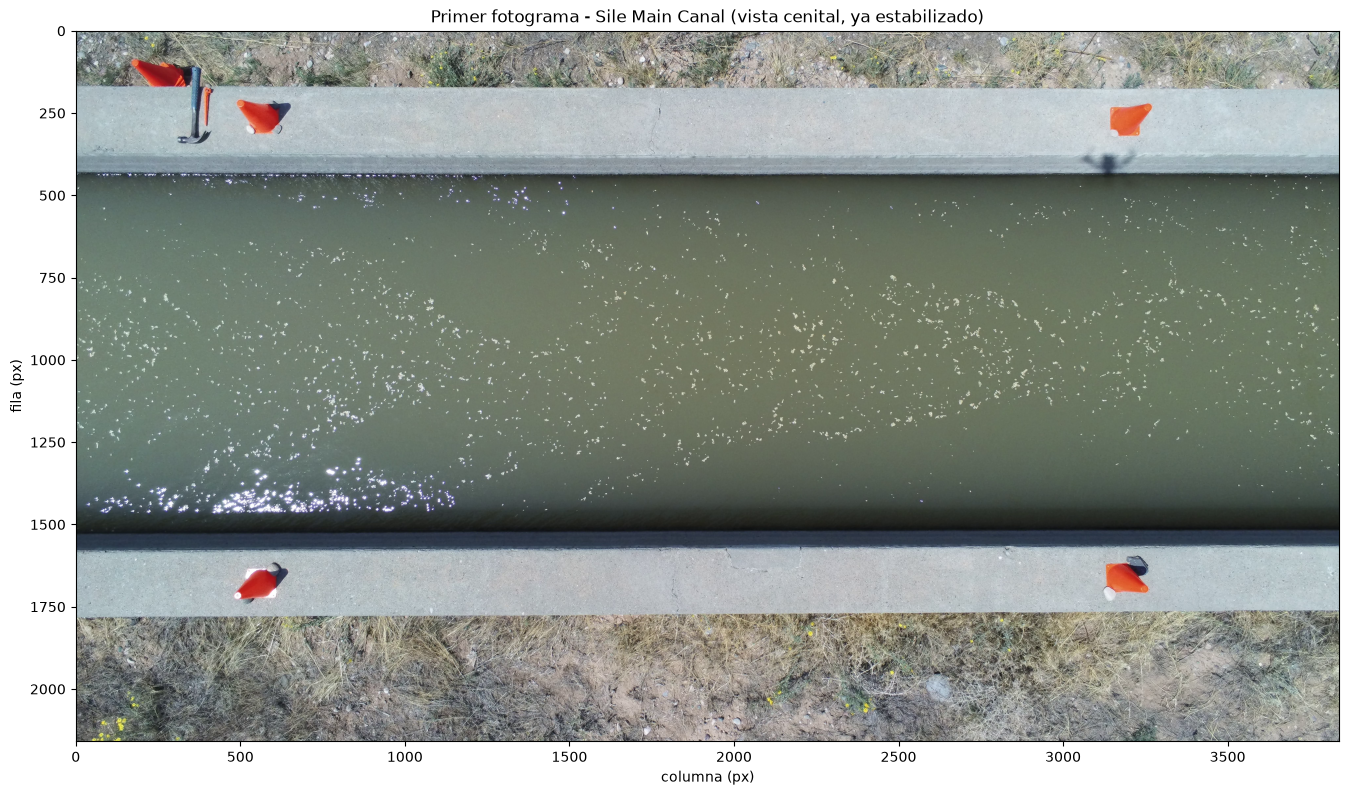

In [2]:
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
if not cap.isOpened():
    raise SystemExit(f"No se pudo abrir {ARCHIVO_VIDEO}. Genera el video con estabilizar_stiv.py.")

FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ANCHO_PX = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO_PX = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
ok, frame_bgr = cap.read()
cap.release()

# DT es el intervalo entre fotogramas: aparece en la formula final de la velocidad.
DT = 1.0 / FPS
# OpenCV lee en BGR; matplotlib espera RGB.
frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

print(f"Resolucion : {ANCHO_PX} x {ALTO_PX} px")
print(f"Cadencia   : {FPS:.4f} fps  ->  DT = {DT*1000:.3f} ms entre fotogramas")
print(f"Fotogramas : {N_TOTAL} ({N_TOTAL/FPS:.1f} s)")

plt.figure(figsize=(14, 8))
plt.imshow(frame_rgb)
plt.title("Primer fotograma - Sile Main Canal (vista cenital, ya estabilizado)")
plt.xlabel("columna (px)"); plt.ylabel("fila (px)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig1_primer_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Escala y geometria de la seccion

Dos cosas se resuelven aqui, y las dos salen del bloque de constantes que abre la celda de codigo.

### La escala

Con el ancho real de la lamina de agua y las dos filas donde toca cada muro, la escala es una regla
de tres:

$$ e \;[\mathrm{m/px}] \;=\; \frac{B}{f_{\mathrm{inf}} - f_{\mathrm{sup}}} $$

Es el numero mas delicado del notebook: **toda la velocidad, y por tanto todo el caudal, es
proporcional a $e$**. La transicion agua-muro no es un escalon perfecto sino una zona de unos 5 px,
asi que esa es la incertidumbre irreducible.

### Las lineas de busqueda

Se coloca **una linea por vertical del aforo**, leyendo las progresivas del propio CSV de la
seccion. Asi cada velocidad tiene su pareja exacta en el aforo y la integracion reproduce el mismo
convenio *mid-section*, sin remuestrear nada. La fila de la imagen de cada estacion sale de la
escala:

$$ f_i = f_{\mathrm{sup}} + \frac{s_i}{e} $$

Las verticales con **profundidad cero** son los extremos de la seccion: caen sobre la propia linea
de agua, no aportan caudal y, por la condicion de no deslizamiento, la velocidad en el muro es nula.
No se miden: se les **impone** $v = 0$.

In [3]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria: lo unico que liga pixeles con metros
# ---------------------------------------------------------------------------------------
# Filas de la imagen donde el agua toca cada muro. Hacen el mismo papel que los GCPs de un
# caso oblicuo. Se leen a ojo sobre el primer fotograma, o con pixel_locator.py; las dos
# ampliaciones de la figura de abajo estan puestas para poder comprobarlas.
FILA_AGUA_SUP = 438
# El muro inferior no da un escalon de brillo como el superior: el hormigon queda en
# sombra y se parece al agua oscura, asi que a ojo se confunde el final del agua con la
# base del muro. Se resuelve con el criterio fisico, que no necesita la referencia: el
# agua se mueve y el hormigon no. La desviacion tipica temporal por fila, medida sobre
# el tramo de columnas 600-3400, cae de 7.1 a 1.3 niveles de gris entre las filas 1460 y
# 1465, y cruza el punto medio en la 1463. 1520 era el otro extremo de la banda de
# sombra, 57 px mas abajo: ensanchaba la lamina un 5 % y dejaba la escala igual de
# gruesa, con todas las velocidades bajas en esa misma proporcion.
FILA_AGUA_INF = 1463

# Ancho real de la lamina de agua entre esas dos filas: 6 ft exactos. Es la unica distancia
# conocida de todo el notebook, y de ella sale la escala. (obtenido del dataset)
ANCHO_CANAL = 1.8288          # m

# Tramo de columnas sobre el que se muestrea cada linea de busqueda. Mas largo da mejor
# estadistica, pero se acerca a los bordes de la imagen, donde la distorsion de la lente
# del dron es mayor y aqui no hay modelo para corregirla.
COLUMNA_INI, COLUMNA_FIN = 600, 3400

# Angulo de las lineas respecto a las filas de la imagen: es la direccion del flujo, que
# STIV necesita saber de antemano. 0 = el cauce corre paralelo a la imagen. La figura de
# abajo dibuja las lineas con este angulo para poder comprobarlo a ojo.
ANGULO_FLUJO = -1.0           # grados
# ---------------------------------------------------------------------------------------

# El CSV trae dos columnas: Progresiva (distancia desde la orilla izquierda, m) y Prof (m).
# Es la geometria que midio el hidrografo en el aforo. (obtenido del dataset)
seccion = pd.read_csv(ARCHIVO_SECCION)
s_estaciones = seccion["Progresiva"].to_numpy(float)
prof_estaciones = seccion["Prof"].to_numpy(float)
N_ESTACIONES = len(seccion)

# Las verticales de profundidad nula son los extremos: no se miden, se les impone v = 0.
ES_CONTORNO = prof_estaciones == 0.0

print(f"Seccion del aforo ({N_ESTACIONES} verticales):")
print(seccion.to_string(index=False))
print(f"\nVerticales con velocidad impuesta a 0: {np.where(ES_CONTORNO)[0].tolist()}")

Seccion del aforo (13 verticales):
 Progresiva  Prof
       0.00 0.000
       0.15 1.073
       0.30 1.073
       0.46 1.073
       0.61 1.073
       0.76 1.073
       0.91 1.073
       1.07 1.073
       1.22 1.073
       1.37 1.073
       1.52 1.073
       1.68 1.073
       1.83 0.000

Verticales con velocidad impuesta a 0: [0, 12]


Ancho del canal en la imagen: 1025 px = 1.8288 m
ESCALA = 1.7842 mm/px
Incertidumbre: la transicion agua-muro ocupa ~5 px, o sea 0.49 % en la escala, y lo mismo en el caudal.

Longitud de cada linea de busqueda: 2800 px = 5.00 m de canal


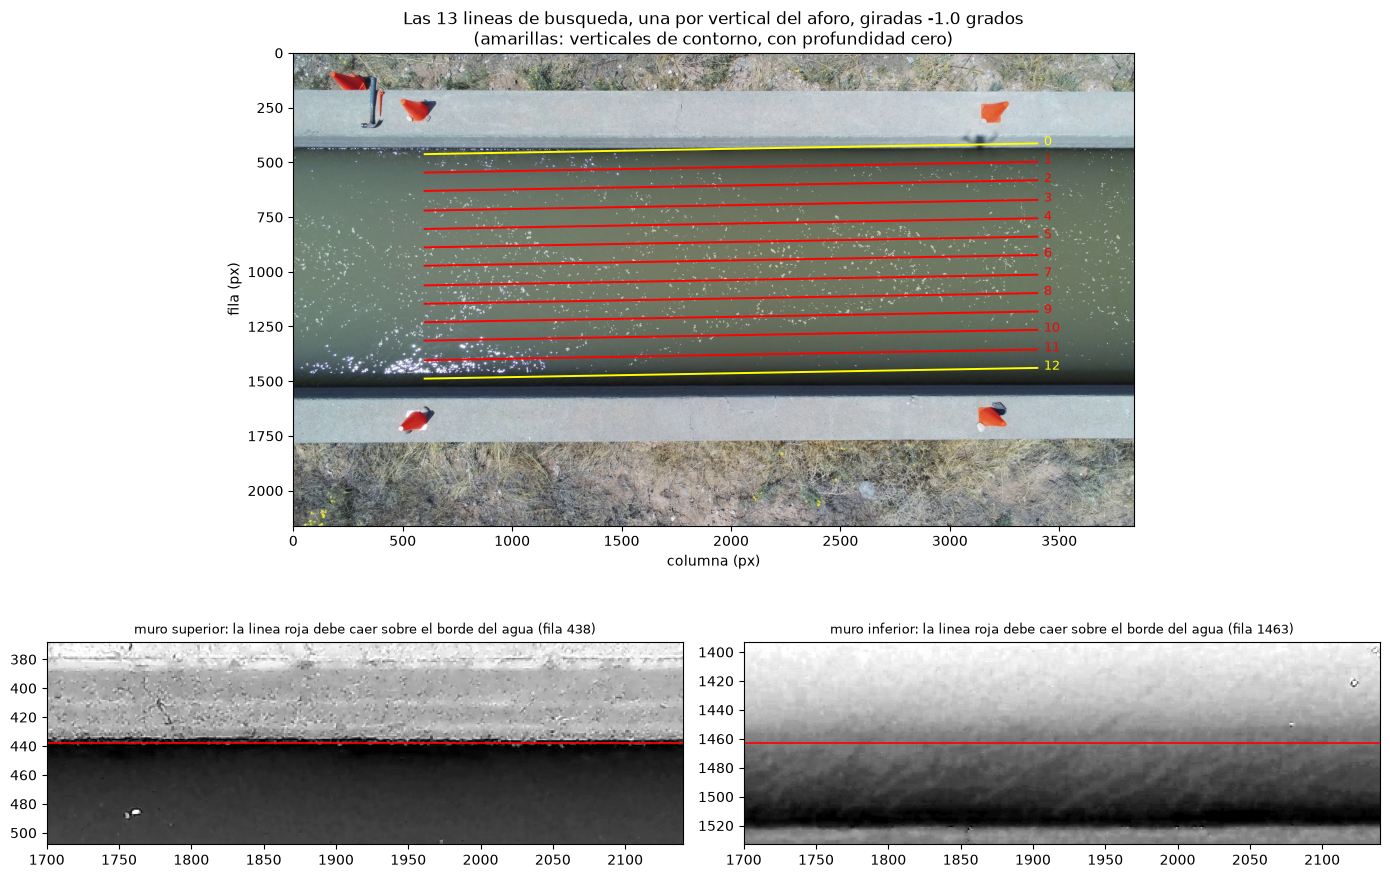

In [4]:
# La escala: metros por pixel de la imagen original.
ANCHO_IMAGEN_PX = FILA_AGUA_INF - FILA_AGUA_SUP
ESCALA = ANCHO_CANAL / ANCHO_IMAGEN_PX

# Fila de la imagen que le corresponde a cada vertical del aforo.
filas_estaciones = FILA_AGUA_SUP + s_estaciones / ESCALA
LARGO_LINEA_M = (COLUMNA_FIN - COLUMNA_INI) * ESCALA

print(f"Ancho del canal en la imagen: {ANCHO_IMAGEN_PX} px = {ANCHO_CANAL} m")
print(f"ESCALA = {ESCALA*1000:.4f} mm/px")
print(f"Incertidumbre: la transicion agua-muro ocupa ~5 px, o sea "
      f"{100*5/ANCHO_IMAGEN_PX:.2f} % en la escala, y lo mismo en el caudal.")
print(f"\nLongitud de cada linea de busqueda: {COLUMNA_FIN-COLUMNA_INI} px = {LARGO_LINEA_M:.2f} m de canal")

# Comprobacion visual: las lineas sobre el fotograma, y las dos laminas de agua ampliadas.
# Cada linea se dibuja girada ANGULO_FLUJO alrededor de su punto medio, que es exactamente
# como se va a muestrear en la Parte 3.
cx = 0.5 * (COLUMNA_INI + COLUMNA_FIN)
dx = 0.5 * (COLUMNA_FIN - COLUMNA_INI) * np.cos(np.radians(ANGULO_FLUJO))
dy = 0.5 * (COLUMNA_FIN - COLUMNA_INI) * np.sin(np.radians(ANGULO_FLUJO))

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(2, 1, 1)
ax.imshow(frame_rgb)
for i, f in enumerate(filas_estaciones):
    color = "yellow" if ES_CONTORNO[i] else "red"
    ax.plot([cx - dx, cx + dx], [f - dy, f + dy], color=color, lw=1.4)
    ax.text(cx + dx + 30, f + dy + 8, f"{i}", color=color, fontsize=9)
ax.set_title(f"Las {N_ESTACIONES} lineas de busqueda, una por vertical del aforo, "
             f"giradas {ANGULO_FLUJO:+.1f} grados\n"
             "(amarillas: verticales de contorno, con profundidad cero)")
ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")

for i, (f, etq) in enumerate([(FILA_AGUA_SUP, "muro superior"), (FILA_AGUA_INF, "muro inferior")]):
    axz = fig.add_subplot(2, 2, 3 + i)
    r0, r1, c0, c1 = f - 70, f + 70, 1700, 2140
    # En gris y con el contraste estirado entre percentiles: el muro inferior esta en sombra y
    # sin estirar no se distingue del agua, que es justo lo que hay que comprobar aqui.
    zoom = cv2.cvtColor(frame_rgb[r0:r1, c0:c1], cv2.COLOR_RGB2GRAY)
    axz.imshow(zoom, cmap="gray", extent=[c0, c1, r1, r0],
               vmin=np.percentile(zoom, 1), vmax=np.percentile(zoom, 99))
    axz.axhline(f, color="r", lw=1.2)
    axz.set_title(f"{etq}: la linea roja debe caer sobre el borde del agua (fila {f})", fontsize=9)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Construccion de las imagenes espacio-temporales

### El paso de muestreo, que es la decision importante

La STI **no** se lee pixel a pixel: se muestrea la linea cada $\Delta s$ pixeles, y esa eleccion fija
el angulo de las estelas. Con la escala y la cadencia de este video, el agua avanza

$$ d = \frac{u\,\Delta t}{e} \approx \frac{0.95 \times 0.0333}{0.00178} \approx 18\ \text{px por fotograma} $$

Si se leyera un pixel por muestra, cada fila de la STI se desplazaria 18 columnas respecto a la
anterior y las estelas quedarian a $\arctan(18) = 87^\circ$, practicamente horizontales. Ahi la
medida del angulo es pesima. Muestreando cada $\Delta s$ pixeles la pendiente en unidades de la STI
es $m = d/\Delta s$, y derivando $u \propto \tan\theta$:

$$ \frac{\delta u}{u} = \frac{\delta\theta}{\sin\theta\,\cos\theta} $$

el denominador es maximo en $\theta = 45^\circ$, o sea $m = 1$. La regla queda trivial:

$$ \boxed{\;\Delta s = d\;} \qquad \text{(el paso de muestreo iguala al desplazamiento por fotograma)} $$

A $87^\circ$ el mismo error de angulo pesaria **19 veces mas** que a $45^\circ$. Por eso la
configuracion pide `V_ESPERADA` y no $\Delta s$ directamente: es mas facil estimar una velocidad
que un paso de muestreo.

### El filtro antialias

Tomar una muestra cada 18 px de una textura cuyos detalles miden 10-20 px es submuestrear, y eso
produce **aliasing**: estructuras falsas con orientaciones inventadas. Como en cualquier remuestreo,
antes hay que filtrar paso bajo con

$$ \sigma = \tfrac{1}{2}\,\Delta s $$

El filtro es **isotropo a proposito**: al promediar tambien *a traves* de la linea (unos 3.5 cm) le
da a la linea de busqueda una **anchura efectiva**, que suprime la turbulencia de pequena escala.
Esa turbulencia no viaja con la corriente y solo decorrela la STI. Es el equivalente de la anchura
de linea que usan las implementaciones habituales de STIV.

### El muestreo

Para una linea que pasa por la fila $f$ con un angulo $\alpha$, la muestra $j$ del fotograma $k$ se
lee en

$$ x_j = c_x + \left(j - \tfrac{N-1}{2}\right)\Delta s\,\cos\alpha, \qquad
   y_j = f   + \left(j - \tfrac{N-1}{2}\right)\Delta s\,\sin\alpha $$

y se interpola bilinealmente con `cv2.remap`, porque esas coordenadas no caen en pixeles enteros:

$$ \mathrm{STI}[k, j] = I_k(x_j, y_j) $$

Todas las lineas se muestrean en la **misma pasada** sobre el video: leer y filtrar un fotograma 4K
es lo caro, y el `remap` de unas cuantas lineas es casi gratis al lado.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Muestreo de la STI
# ---------------------------------------------------------------------------------------
# Orden de magnitud de la velocidad superficial. No es un resultado ni un dato de
# validacion: es una estimacion a ojo, del tipo que da cualquiera con el rio delante. De
# aqui sale el paso de muestreo DS, y cerca del optimo la curva es tan plana que
# equivocarse un 30 % apenas cambia el resultado.
V_ESPERADA = 0.95             # m/s

# Fotogramas a procesar. Cuantos mas, mejor estadistica en la STI, y mas tiempo de lectura.
# 250 a 30 fps son 8.3 s de canal.
N_FRAMES = 250
# ---------------------------------------------------------------------------------------

# El paso de muestreo sale de la velocidad esperada: DS = d, para que las estelas caigan a 45 grados.
D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))                  # se redondea: afinar mas no aporta nada
SIGMA_ANTIALIAS = 0.5 * DS                   # filtro paso bajo obligatorio antes de submuestrear

print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma")
print(f"  -> paso de muestreo  DS    = {DS} px  ({DS*ESCALA*100:.2f} cm)")
print(f"  -> filtro antialias  SIGMA = {SIGMA_ANTIALIAS:.1f} px  ({SIGMA_ANTIALIAS*ESCALA*100:.2f} cm)")
print(f"  -> estelas a {np.degrees(np.arctan(D_ESPERADO/DS)):.1f} grados")


def mapa_lineas(filas, angulos_deg, ds, x0=None, x1=None):
    """Coordenadas de muestreo de cada linea. Devuelve mapx, mapy de forma (n_lineas, n_muestras).

    `filas` y `angulos_deg` deben tener la misma longitud (una entrada por linea).
    """
    x0 = COLUMNA_INI if x0 is None else x0
    x1 = COLUMNA_FIN if x1 is None else x1
    filas = np.atleast_1d(np.asarray(filas, float))
    angs = np.radians(np.atleast_1d(np.asarray(angulos_deg, float)))
    n_mu = int((x1 - x0) / ds)
    # t recorre la linea centrada en su punto medio, en pixeles
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    cx = 0.5 * (x0 + x1)
    mapx = np.zeros((len(filas), n_mu), np.float32)
    mapy = np.zeros((len(filas), n_mu), np.float32)
    for i, (f, a) in enumerate(zip(filas, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = f + t * np.sin(a)
    return mapx, mapy


def construir_sti(archivo, mapx, mapy, n_frames, sigma):
    """Apila n_frames filas muestreadas -> STI de forma (n_lineas, n_frames, n_muestras)."""
    cap = cv2.VideoCapture(str(archivo))
    sti = np.zeros((mapx.shape[0], n_frames, mapx.shape[1]), np.float32)
    for k in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            sti = sti[:, :k, :]
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        # Antialias ANTES de muestrear: sin esto el submuestreo inventa orientaciones.
        gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        sti[:, k, :] = cv2.remap(gris, mapx, mapy, cv2.INTER_LINEAR)
    cap.release()
    return sti


mapx, mapy = mapa_lineas(filas_estaciones, np.full(N_ESTACIONES, ANGULO_FLUJO), DS)

# Unica pasada sobre el video, y con diferencia el bloque mas caro del notebook: decodificar,
# pasar a gris y filtrar 250 fotogramas de 3840x2160.
with benchmark.medir("Parte 3: construir las STI (unica pasada sobre el video)",
                     n_frames=N_FRAMES, lineas=N_ESTACIONES):
    sti_crudo = construir_sti(ARCHIVO_VIDEO, mapx, mapy, N_FRAMES, SIGMA_ANTIALIAS)

print(f"\nSTI construidas: {sti_crudo.shape[0]} lineas x {sti_crudo.shape[1]} fotogramas "
      f"x {sti_crudo.shape[2]} muestras")
print(f"Cada STI cubre {sti_crudo.shape[1]*DT:.2f} s de tiempo y {LARGO_LINEA_M:.2f} m de canal")

Desplazamiento esperado: 17.74 px/fotograma
  -> paso de muestreo  DS    = 18 px  (3.21 cm)
  -> filtro antialias  SIGMA = 9.0 px  (1.61 cm)
  -> estelas a 44.6 grados


  [bench] Parte 3: construir las STI (unica pasada sobre el video): 33.8 s | CPU 122.8 s (3.6 nucleos) | RAM pico 869 MB

STI construidas: 13 lineas x 250 fotogramas x 155 muestras
Cada STI cubre 8.33 s de tiempo y 5.00 m de canal


### Preparacion de la STI

La STI recien construida no se puede meter directamente en el tensor: contiene dos cosas que no son
la senal y que dominarian el resultado.

1. **El fondo estatico.** Cada muestra tiene su propio brillo medio (un reflejo fijo, una mancha del
   hormigon). En la STI eso son **rayas verticales** perfectas, que el tensor leeria como "velocidad
   cero" con muchisima energia. Se quita restando la media temporal de cada muestra:

   $$ A[k,j] = \mathrm{STI}[k,j] - \frac{1}{N_t}\sum_{k'} \mathrm{STI}[k',j] $$

   Es el equivalente exacto del `normalize` de las implementaciones de LSPIV.

2. **El parpadeo global.** Si un fotograma entero sale mas claro, eso son **rayas horizontales**, que
   el tensor leeria como velocidad infinita. Se quita restando la media espacial de cada fotograma:

   $$ B[k,j] = A[k,j] - \frac{1}{N_x}\sum_{j'} A[k,j'] $$

Por ultimo se divide por la desviacion tipica global, que no cambia la orientacion (el tensor es
invariante a escala) pero deja todas las STI comparables entre si.

  [bench] Parte 3: preparar las STI: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 274 MB


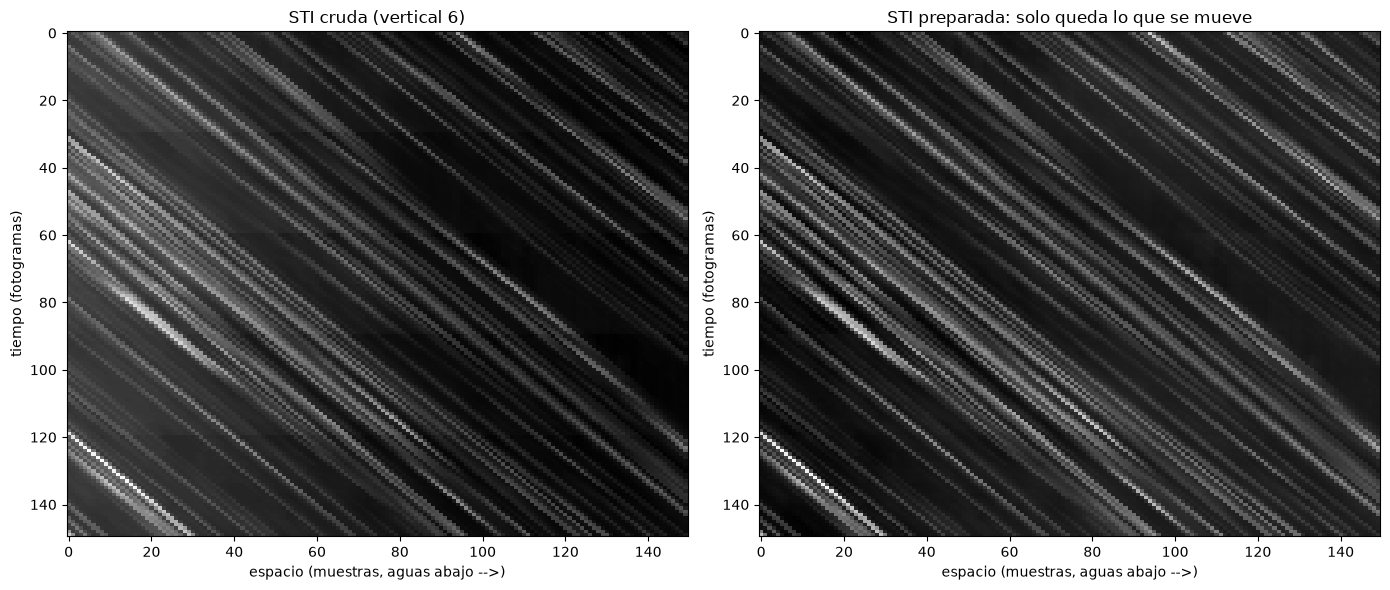

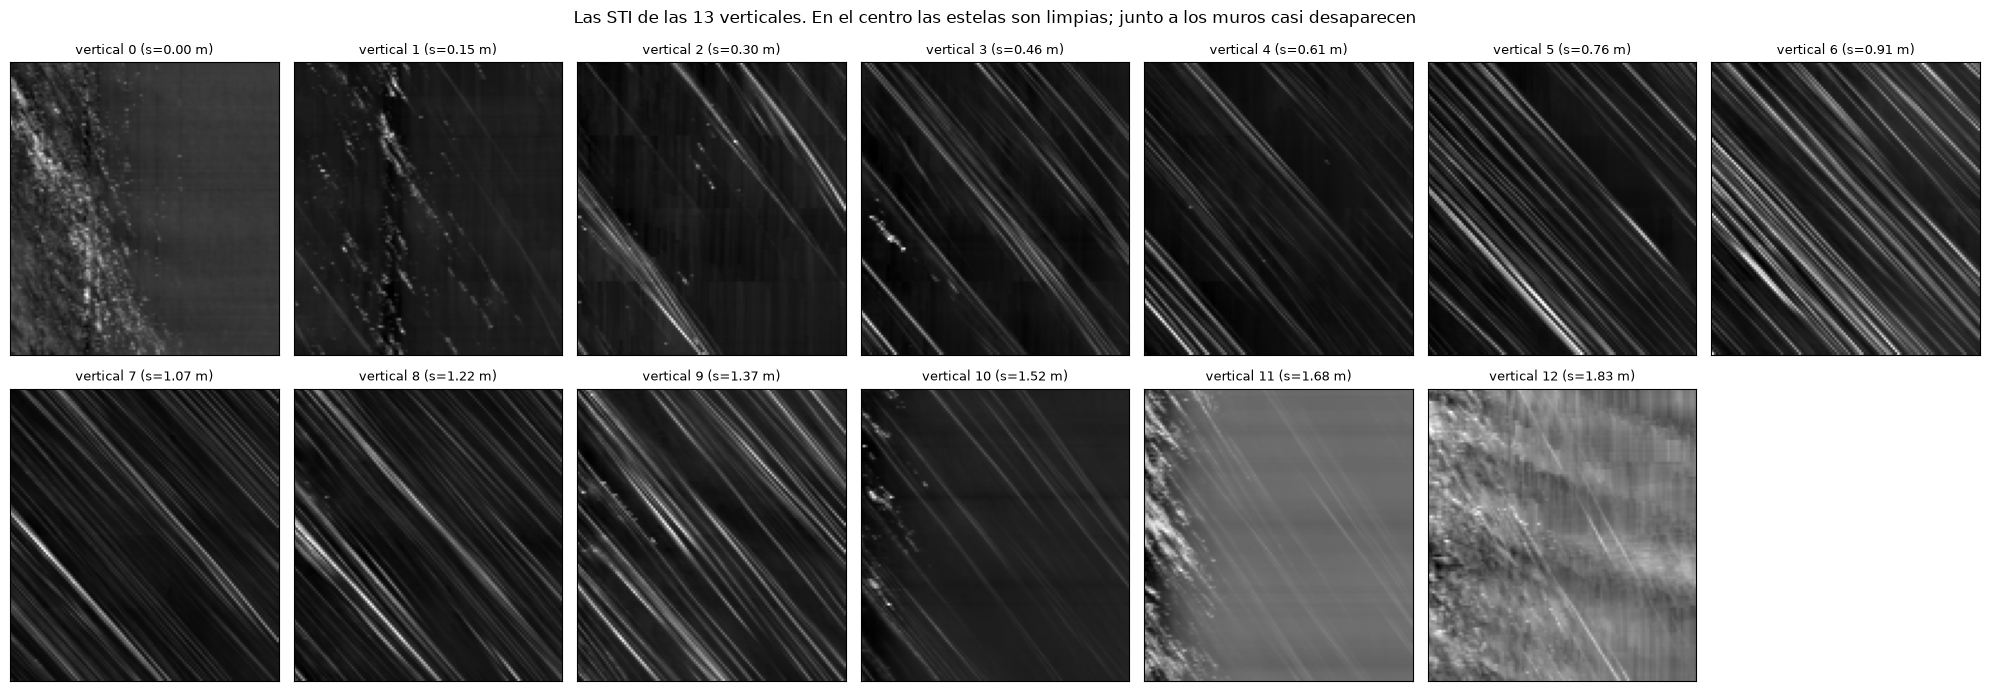

In [6]:
def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # 1) fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # 2) parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a

with benchmark.medir("Parte 3: preparar las STI", lineas=N_ESTACIONES):
    sti_prep = np.stack([preparar_sti(s) for s in sti_crudo])

# Efecto de la preparacion sobre una vertical central.
i_demo = N_ESTACIONES // 2
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(sti_crudo[i_demo][:150, :150], cmap="gray", aspect="auto")
axes[0].set_title(f"STI cruda (vertical {i_demo})")
axes[1].imshow(sti_prep[i_demo][:150, :150], cmap="gray", aspect="auto")
axes[1].set_title("STI preparada: solo queda lo que se mueve")
for ax in axes:
    ax.set_xlabel("espacio (muestras, aguas abajo -->)")
    ax.set_ylabel("tiempo (fotogramas)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig3_preparacion_sti.png", dpi=110, bbox_inches="tight")
plt.show()

# Todas las verticales, para ver como se degradan las estelas al acercarse a los muros.
fig, axes = plt.subplots(2, 7, figsize=(20, 7))
for i, ax in enumerate(axes.ravel()):
    if i >= N_ESTACIONES:
        ax.axis("off"); continue
    ax.imshow(sti_prep[i][:120, :120], cmap="gray", aspect="auto")
    ax.set_title(f"vertical {i} (s={s_estaciones[i]:.2f} m)", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Las STI de las 13 verticales. En el centro las estelas son limpias; "
             "junto a los muros casi desaparecen", fontsize=12)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_todas_las_sti.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidad con el tensor de estructura

Solo queda medir la orientacion dominante de las estelas. La herramienta estandar para eso es el
**tensor de estructura del gradiente**.

Sobre la STI preparada se calculan las dos derivadas parciales, en espacio y en tiempo:

$$ I_x = \frac{\partial B}{\partial x}, \qquad I_t = \frac{\partial B}{\partial t} $$

(con un operador de Sobel de 3x3, precedido de un suavizado gaussiano leve que hace la derivada
menos sensible al ruido de pixel). Con ellas se forma la matriz simetrica 2x2

$$ J \;=\; \begin{pmatrix} \sum I_x^2 & \sum I_x I_t \\[2pt] \sum I_x I_t & \sum I_t^2 \end{pmatrix}
\;=\;\begin{pmatrix} J_{xx} & J_{xt} \\ J_{xt} & J_{tt} \end{pmatrix} $$

El gradiente de una estela apunta **perpendicular** a ella, asi que el autovector del autovalor
**menor** apunta **a lo largo** de las estelas, que es lo que buscamos. Si ese autovector es
$(e_x, e_t)$, la pendiente de la estela es

$$ m = \frac{e_x}{e_t} \qquad \text{[muestras de espacio por fotograma]} $$

$m$ sale **con signo**, asi que el metodo distingue tambien el sentido del flujo.

### La coherencia

El tensor viene con una medida de calidad gratis:

$$ C \;=\; \frac{\lambda_1 - \lambda_2}{\lambda_1 + \lambda_2}
      \;=\; \frac{\sqrt{(J_{xx}-J_{tt})^2 + 4J_{xt}^2}}{J_{xx}+J_{tt}} \;\in[0,1] $$

$C = 1$ significa que toda la textura apunta en la misma direccion (estelas perfectas); $C = 0$, que
no hay direccion privilegiada (ruido isotropo). $C = 0.7$ equivale a
$\lambda_1/\lambda_2 = (1+C)/(1-C) \approx 5.7$. Ese es el criterio de calidad de la Parte 4b.

### La velocidad

Encadenando todas las conversiones:

$$ \boxed{\;u \;=\; m \cdot \Delta s \cdot e \cdot \frac{1}{\Delta t}\;}
\qquad
\underbrace{m}_{\text{muestras/fotograma}}\;
\underbrace{\Delta s}_{\text{px/muestra}}\;
\underbrace{e}_{\text{m/px}}\;
\underbrace{1/\Delta t}_{\text{fotogramas/s}} $$

### Por bloques, no de golpe

Aplicar el tensor a la STI entera es fragil: un unico parche muy contrastado (un reflejo del sol, un
grumo de espuma brillante) aporta tanta energia que puede imponer su orientacion sobre el resto. Por
eso la STI se divide en **bloques con 50 % de solape**, se mide cada uno por separado y se combinan
con una **mediana ponderada por coherencia**, que descarta los bloques mudos y no deja que ninguno
mande solo.

Vertical 6, bloque de 128x128:
  pendiente m  = 1.0137 muestras/fotograma  (45.39 grados)
  coherencia C = 0.9772   ->  lambda1/lambda2 = 86.6
  velocidad    = 0.9772 m/s


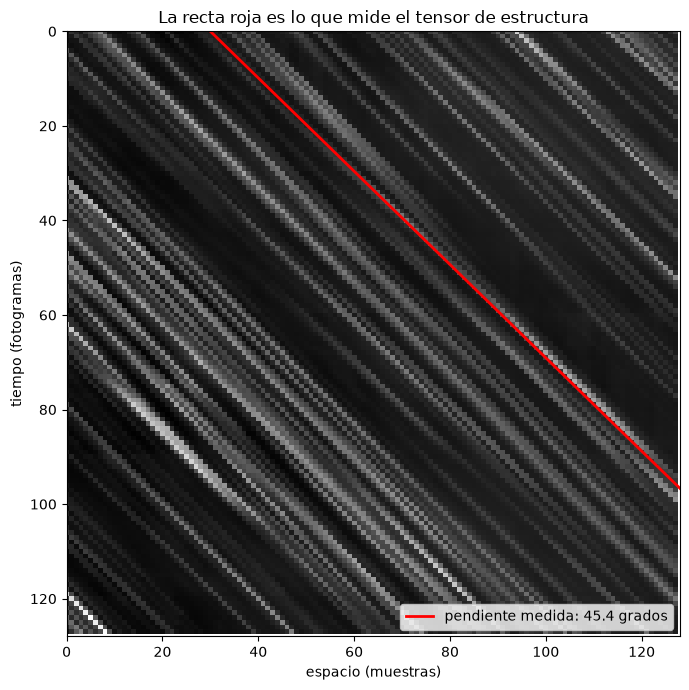

In [7]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Parametros del estimador
# ---------------------------------------------------------------------------------------
# Lado del bloque de STI sobre el que se resuelve un tensor, en pixeles de STI. Con los
# valores de este caso, 64 px son ~2 s de tiempo y ~1.2 m de canal. Mas grande promedia
# mas y aguanta mejor el ruido; mas pequeno detecta variaciones locales pero es fragil.
LADO_BLOQUE = 64

# Coherencia minima para que un bloque entre en la mediana. Los bloques por debajo son los
# que no tienen ninguna orientacion dominante: agua lisa, sombra, zonas sin espuma.
COH_MIN_BLOQUE = 0.50

# Suavizado gaussiano previo a las derivadas de Sobel, en pixeles de STI. Hace la derivada
# menos sensible al ruido de pixel sin llegar a borrar las estelas.
SIGMA_DERIVADA = 1.5
# ---------------------------------------------------------------------------------------


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    g = cv2.GaussianBlur(bloque, (0, 0), sigma)
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    Ix = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    # se recorta el borde: Sobel contamina 2 px por el efecto de borde
    It, Ix = It[2:-2, 2:-2], Ix[2:-2, 2:-2]

    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0

    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE):
    """Pendiente robusta de una STI completa, por bloques con solape."""
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado])
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    ms, cs = np.array(ms), np.array(cs)
    if len(ms) == 0:
        return np.nan, 0.0, 0, 0
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana, 0, len(ms)
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    m_rob = float(mm[np.searchsorted(acumulado, 0.5)])
    return m_rob, coh_mediana, int(usables.sum()), len(ms)


def pendiente_a_velocidad(m):
    """m [muestras/fotograma] -> u [m/s]."""
    return m * DS * ESCALA / DT


# Demostracion sobre una vertical central: se dibuja encima la pendiente que sale del tensor.
m_demo, c_demo = tensor_estructura(sti_prep[i_demo][:128, :128])
print(f"Vertical {i_demo}, bloque de 128x128:")
print(f"  pendiente m  = {m_demo:.4f} muestras/fotograma  ({np.degrees(np.arctan(m_demo)):.2f} grados)")
print(f"  coherencia C = {c_demo:.4f}   ->  lambda1/lambda2 = {(1+c_demo)/(1-c_demo):.1f}")
print(f"  velocidad    = {pendiente_a_velocidad(m_demo):.4f} m/s")

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(sti_prep[i_demo][:128, :128], cmap="gray", aspect="auto")
tt = np.array([0, 127])
ax.plot(30 + m_demo * tt, tt, "r-", lw=2,
        label=f"pendiente medida: {np.degrees(np.arctan(m_demo)):.1f} grados")
ax.set_xlim(0, 128); ax.set_ylim(128, 0)
ax.set_xlabel("espacio (muestras)"); ax.set_ylabel("tiempo (fotogramas)")
ax.set_title("La recta roja es lo que mide el tensor de estructura")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_tensor.png", dpi=110, bbox_inches="tight")
plt.show()

In [8]:
v_stiv = np.full(N_ESTACIONES, np.nan)
coherencia = np.full(N_ESTACIONES, np.nan)
bloques_ok = np.zeros(N_ESTACIONES, int)
bloques_tot = np.zeros(N_ESTACIONES, int)

with benchmark.medir("Parte 4: tensor de estructura en todas las verticales", lineas=N_ESTACIONES):
    for i in range(N_ESTACIONES):
        if ES_CONTORNO[i]:
            # condicion de contorno: profundidad nula y no deslizamiento en el muro
            v_stiv[i] = 0.0
            continue
        m, c, nok, ntot = medir_sti(sti_prep[i])
        v_stiv[i] = pendiente_a_velocidad(m) if np.isfinite(m) else np.nan
        coherencia[i] = c
        bloques_ok[i], bloques_tot[i] = nok, ntot

# La coherencia y el numero de bloques utiles son las dos cifras que dicen si hay que fiarse.
# Aqui solo se miden y se muestran; el criterio de aceptacion se aplica en la Parte 4b.
resultados = pd.DataFrame({
    "estacion": np.arange(N_ESTACIONES),
    "s_m": s_estaciones,
    "fila_px": filas_estaciones.round(1),
    "v_stiv_ms": v_stiv,
    "coherencia": coherencia,
    "bloques": [f"{a}/{b}" for a, b in zip(bloques_ok, bloques_tot)],
})
print(resultados.to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  [bench] Parte 4: tensor de estructura en todas las verticales: 0.0 s | CPU 0.0 s (1.0 nucleos) | RAM pico 296 MB
 estacion      s_m   fila_px  v_stiv_ms  coherencia bloques
        0   0.0000  438.0000     0.0000         NaN     0/0
        1   0.1500  522.1000     0.5865      0.5436   12/18
        2   0.3000  606.1000     0.7316      0.7782   16/18
        3   0.4600  695.8000     0.8365      0.9430   18/18
        4   0.6100  779.9000     0.8784      0.9698   18/18
        5   0.7600  864.0000     0.9615      0.9736   18/18
        6   0.9100  948.0000     0.9738      0.9747   18/18
        7   1.0700 1037.7000     0.9420      0.9771   18/18
        8   1.2200 1121.8000     0.9560      0.9713   18/18
        9   1.3700 1205.9000     0.8939      0.9619   18/18
       10   1.5200 1289.9000     0.8488      0.8823   17/18
       11   1.6800 1379.6000     1.3448      0.6113   17/18
       12   1.8300 1463.7000     0.0000         NaN     0/0


---
## Parte 4b - Control de calidad y relleno de los huecos

Paso imprescindible, y el equivalente exacto del filtrado de mascaras de un flujo LSPIV. Las
verticales que no llegan a $C \ge 0.70$ se descartan. No es un capricho: son siempre las pegadas al
hormigon, y por una razon fisica que se ve en la figura 4. Alli el agua va lenta, apenas arrastra
espuma y la franja esta parcialmente en sombra del muro; a la STI le quedan pocas estelas y muy
tenues, de modo que el tensor mide sobre todo ondas superficiales y reflejos, que **no viajan a la
velocidad de la corriente**. Sin este filtro esas verticales entran en el caudal con valores que
pueden ser mayores que los del centro del canal, lo cual es fisicamente imposible.

Los huecos se rellenan por **interpolacion lineal** entre las verticales que si valen. Los ceros
de los muros **no** entran como puntos de apoyo: estan donde el CSV da calado cero, asi que no
aportan caudal ni son medidas de velocidad, y usarlos imponia una orilla en rampa a un canal que
es una caja de muros verticales. Fuera del tramo medido la interpolacion mantiene el valor del
extremo:

$$ u(s) \;=\; \mathrm{interp}\big(s;\; \{s_j, u_j\}_{j\ \mathrm{aceptada}}\big) $$

Es el relleno mas simple posible y no introduce ningun parametro nuevo: dice que entre dos
verticales conocidas la velocidad varia de forma monotona, y que junto al muro se parece a la
ultima que se pudo medir. No pretende reproducir la fisica de la capa limite del muro, que en
hormigon liso es mucho mas fina que la separacion entre verticales. Las verticales rellenadas se marcan como tales en la tabla y en la figura, y quedan
recogidas en las limitaciones del final.

Verticales validas: 9 de las 11 medidas

Vertical 1 (s = 0.1500 m, coherencia 0.544): 0.586 -> 0.732 m/s   [interpolada]
Vertical 11 (s = 1.6800 m, coherencia 0.611): 1.345 -> 0.849 m/s   [interpolada]


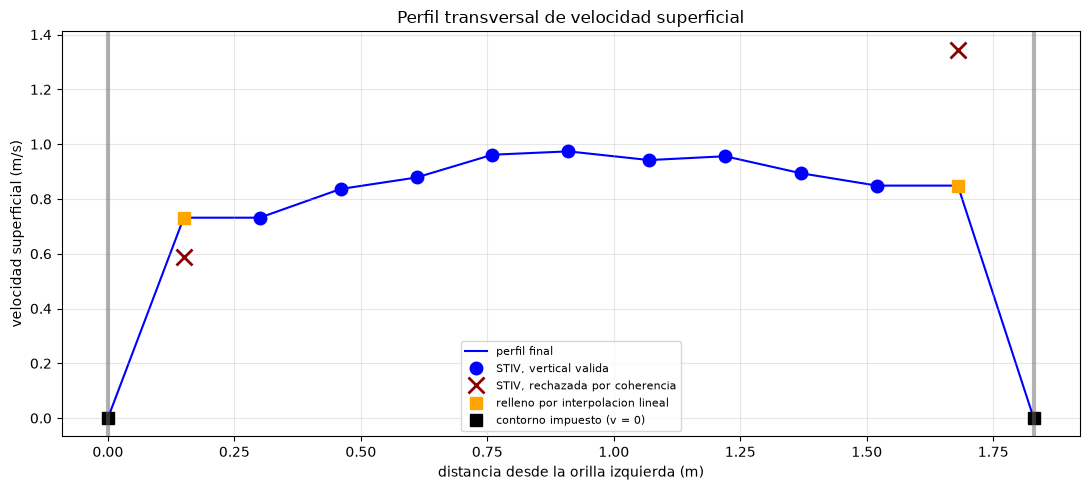


Velocidad superficial maxima: 0.9738 m/s (vertical 6)
Velocidad superficial media en las verticales con calado: 0.8730 m/s


In [9]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterio de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima para dar por buena una vertical. Es el criterio de calidad del
# notebook, y se fija ANTES de ver ningun resultado. 0.70 equivale a que la orientacion
# dominante sea ~6 veces mas fuerte que la perpendicular.
COH_MIN_ESTACION = 0.70
# ---------------------------------------------------------------------------------------

# Se aplica el criterio: una vertical vale si no es contorno, tiene coherencia suficiente
# y el tensor devolvio un numero.
valida = (~ES_CONTORNO) & (coherencia >= COH_MIN_ESTACION) & np.isfinite(v_stiv)
resultados["estado"] = ["contorno" if ES_CONTORNO[i] else ("valida" if valida[i] else "RECHAZADA")
                        for i in range(N_ESTACIONES)]
print(f"Verticales validas: {valida.sum()} de las {(~ES_CONTORNO).sum()} medidas\n")

# Relleno por interpolacion lineal. Se rellenan las verticales rechazadas; las de
# contorno conservan su cero impuesto.
apoyo = valida | ES_CONTORNO
v_final = v_stiv.copy()
rellenadas = np.where(~apoyo)[0]
# Los puntos de apoyo son solo las verticales MEDIDAS. Los ceros del contorno no entran:
# estan en s = 0 y s = 1.83, donde el CSV da calado cero, asi que ni aportan caudal ni son
# medidas de velocidad. Usarlos como apoyo imponia una orilla en rampa a un canal que es
# una caja de hormigon con muros verticales, y arrastraba hacia cero a las verticales 1,
# 10 y 11, que tienen el calado completo de 1.073 m. Fuera del tramo medido np.interp
# mantiene el valor del extremo, que aqui es la hipotesis correcta: la capa limite contra
# un muro liso es mucho mas fina que los 15 cm que separan del muro a la vertical 1.
v_final[rellenadas] = np.interp(s_estaciones[rellenadas],
                                s_estaciones[valida], v_stiv[valida])
for i in rellenadas:
    print(f"Vertical {i} (s = {s_estaciones[i]:.4f} m, coherencia {coherencia[i]:.3f}): "
          f"{v_stiv[i]:.3f} -> {v_final[i]:.3f} m/s   [interpolada]")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(s_estaciones, v_final, "b-", lw=1.5, zorder=1, label="perfil final")
ax.plot(s_estaciones[valida], v_stiv[valida], "bo", ms=9, label="STIV, vertical valida")
rech = (~valida) & (~ES_CONTORNO)
ax.plot(s_estaciones[rech], v_stiv[rech], "x", color="darkred", ms=11, mew=2,
        label="STIV, rechazada por coherencia")
ax.plot(s_estaciones[rech], v_final[rech], "s", color="orange", ms=9,
        label="relleno por interpolacion lineal")
ax.plot(s_estaciones[ES_CONTORNO], v_final[ES_CONTORNO], "ks", ms=9,
        label="contorno impuesto (v = 0)")
for xm in (s_estaciones[0], s_estaciones[-1]):
    ax.axvline(xm, color="dimgray", lw=3, alpha=0.5)
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad superficial (m/s)")
ax.set_title("Perfil transversal de velocidad superficial")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower center")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig6_perfil_superficial.png", dpi=110, bbox_inches="tight")
plt.show()

print(f"\nVelocidad superficial maxima: {v_final.max():.4f} m/s "
      f"(vertical {int(np.argmax(v_final))})")
print(f"Velocidad superficial media en las verticales con calado: "
      f"{v_final[~ES_CONTORNO].mean():.4f} m/s")

---
### Las velocidades sobre el canal

El perfil de arriba, puesto donde se midio. Cada flecha es **una linea de busqueda entera**, no un
punto: STIV promedia a lo largo de los 2800 px muestreados, asi que no hay campo 2D que dibujar
como en LSPIV. La direccion no se mide, se impone (`ANGULO_FLUJO`).

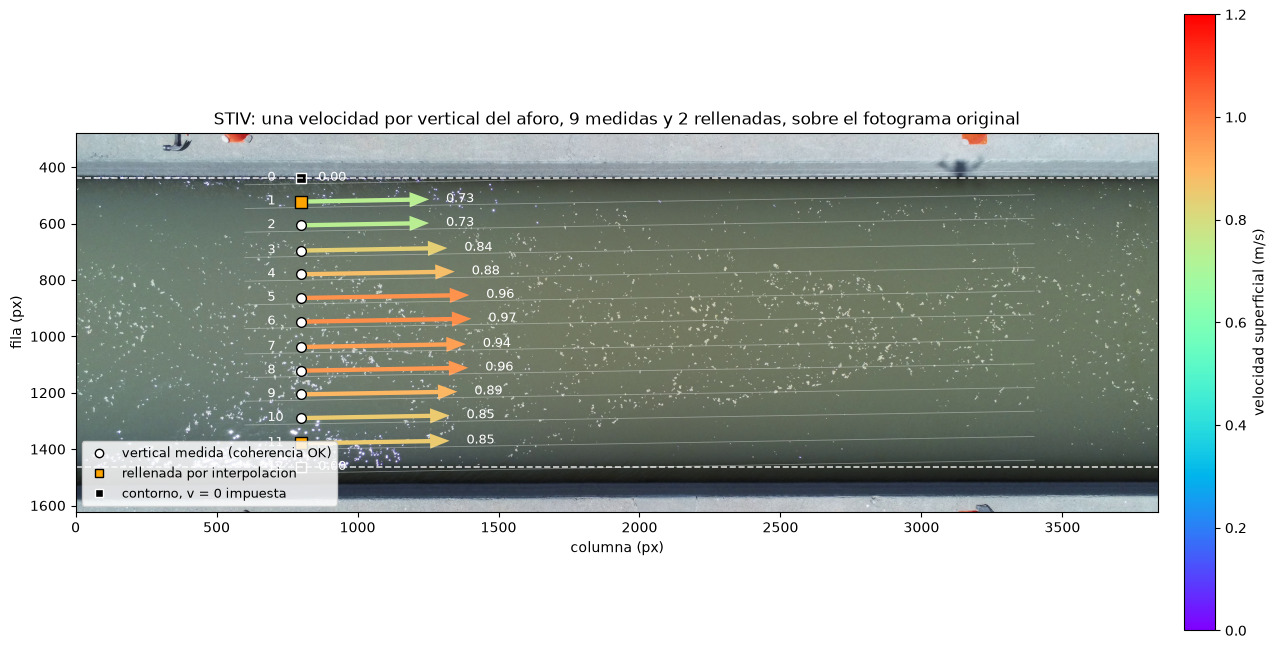

In [10]:
# Las velocidades medidas, dibujadas sobre el propio fotograma. STIV no da un campo 2D sino
# un escalar por linea de busqueda, asi que aqui hay una sola flecha por vertical del aforo,
# colocada sobre su linea y orientada segun ANGULO_FLUJO, que es la direccion que el metodo
# recibe como configuracion. La longitud es proporcional a la velocidad.
PX_POR_MS = 620          # pixeles de flecha por cada m/s, solo para que se vean

ang = np.radians(ANGULO_FLUJO)
u = v_final * PX_POR_MS * np.cos(ang)
w = v_final * PX_POR_MS * np.sin(ang)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(frame_rgb)

# Las lineas de busqueda, tenues, para ver de donde sale cada flecha.
for f in filas_estaciones:
    ax.plot([cx - dx, cx + dx], [f - dy, f + dy], color="w", lw=0.6, alpha=0.35)

# Una flecha por vertical, arrancando a la izquierda del tramo muestreado.
x0 = cx - dx + 200
q = ax.quiver(np.full(N_ESTACIONES, x0), filas_estaciones, u, w, v_final,
              cmap="rainbow", norm=plt.Normalize(vmin=0.0, vmax=1.2),
              angles="xy", scale_units="xy", scale=1,
              width=0.004, headwidth=3.5, headlength=4.5)
fig.colorbar(q, ax=ax, label="velocidad superficial (m/s)", pad=0.02, shrink=0.8)

# El estado de cada vertical: medida, rellenada o contorno impuesto. Es la informacion que
# no se ve en el modulo de la flecha y sin la cual el perfil se lee mal.
for i, f in enumerate(filas_estaciones):
    if ES_CONTORNO[i]:
        ax.plot(x0, f, "ks", ms=7, mec="w")
    elif valida[i]:
        ax.plot(x0, f, "o", color="w", ms=7, mec="k")
    else:
        ax.plot(x0, f, "s", color="orange", ms=8, mec="k")
    ax.text(x0 - 120, f + 10, f"{i}", color="w", fontsize=9)
    ax.text(x0 + u[i] + 60, f + w[i] + 10, f"{v_final[i]:.2f}", color="w", fontsize=9)

ax.plot([], [], "o", color="w", mec="k", label="vertical medida (coherencia OK)")
ax.plot([], [], "s", color="orange", mec="k", label="rellenada por interpolacion")
ax.plot([], [], "ks", mec="w", label="contorno, v = 0 impuesta")
ax.legend(loc="lower left", fontsize=9, framealpha=0.85)

ax.axhline(FILA_AGUA_SUP, color="w", ls="--", lw=1.2, alpha=0.8)
ax.axhline(FILA_AGUA_INF, color="w", ls="--", lw=1.2, alpha=0.8)
ax.set_xlim(0, ANCHO_PX)
ax.set_ylim(FILA_AGUA_INF + 160, FILA_AGUA_SUP - 160)
ax.set_title(f"STIV: una velocidad por vertical del aforo, {int(valida.sum())} medidas y "
             f"{int(len(rellenadas))} rellenadas, sobre el fotograma original")
ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_vectores_canal.png", dpi=130, bbox_inches="tight")
plt.show()


---
## Parte 5 - Caudal sobre la seccion

Quedan dos pasos, y los dos son convenios hidrometricos, no algoritmo.

### 1. De superficie a media en la vertical

STIV, como cualquier tecnica de imagen, solo ve la **superficie**. El caudal necesita la velocidad
**media en la vertical**, que es menor porque el perfil decrece hacia el lecho por rozamiento:

$$ \bar u = \alpha \, u_{\mathrm{sup}}, \qquad \alpha = 0.85 $$

**0.85 es el valor estandar de la practica del USGS.** Se fija al principio de esta parte, antes de
mirar la referencia, y **no se toca despues**. Es el unico parametro del notebook que no se puede
medir en la imagen: hara falta discutirlo en la Parte 7.

### 2. Integracion sobre la seccion

Con la profundidad $h_i$ de cada vertical, el caudal especifico es $q_i = \bar u_i\,h_i$ [m²/s], y el
caudal total se integra por trapecios sobre las progresivas:

$$ Q \;=\; \int_0^B \bar u(s)\,h(s)\,\mathrm{d}s \;\approx\;
\sum_i \frac{q_i + q_{i+1}}{2}\,(s_{i+1}-s_i) $$

### Por que la seccion lleva profundidad cero en los extremos

El hidrografo no midio un area: midio 13 verticales y sumo caudales parciales por el metodo
**mid-section**, en el que las dos verticales de los extremos se registran con profundidad 0. Asi
vienen en el CSV, y asi se usan aqui. Eso da ~1.80 m² en vez de los 1.962 m² que tiene fisicamente
la caja de hormigon (1.8288 x 1.073): la diferencia, un 9 %, son las dos franjas de 7.6 cm junto a
cada muro que el convenio descarta. La eleccion es deliberada, **replicar la geometria del aforo**
para que el caudal sea comparable.

  [bench] Parte 5: integracion del caudal: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 292 MB
Area de la seccion (trapecios sobre el CSV): 1.8026 m2
Velocidad media en la seccion:             0.8030 m/s

CAUDAL ESTIMADO POR STIV: Q = 1.4475 m3/s


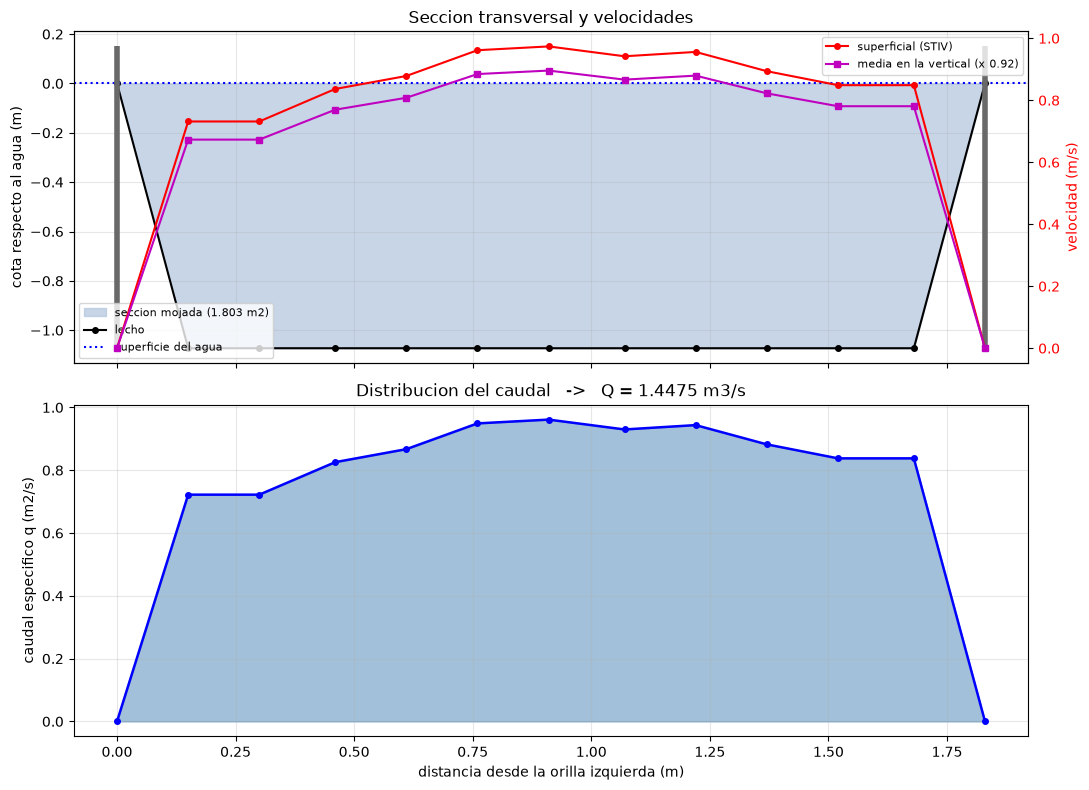

In [11]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Convenio hidrometrico
# ---------------------------------------------------------------------------------------
# Cociente entre la velocidad media en la vertical y la velocidad superficial. Es el unico
# parametro del notebook que NO se puede medir en la imagen: ninguna tecnica de
# velocimetria superficial ve lo que pasa bajo el agua. 0.92 es el estandar de la practica
# del USGS, se fija aqui antes de mirar la referencia, y no se toca despues.
ALFA = 0.92
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 5: integracion del caudal"):
    v_media_vertical = ALFA * v_final
    q_especifico = v_media_vertical * prof_estaciones          # m2/s
    Q_STIV = float(np.trapezoid(q_especifico, s_estaciones))   # m3/s
    # Area por trapecios sobre las mismas progresivas y calados del CSV que se acaban de
    # usar para el caudal: es la misma cuenta que hace el notebook de pyorc, y evita que
    # las dos velocidades medias se comparen sobre areas distintas. La caja fisica de
    # hormigon (1.8288 x 1.073 = 1.9622 m2) es mayor, pero no es lo que el aforo describe.
    AREA = float(np.trapezoid(prof_estaciones, s_estaciones))   # m2
    AREA_CAJA = 1.7988  # m2, valor redondeado que se usaba antes, informativo

print(f"Area de la seccion (trapecios sobre el CSV): {AREA:.4f} m2")
print(f"Velocidad media en la seccion:             {Q_STIV/AREA:.4f} m/s")
print(f"\nCAUDAL ESTIMADO POR STIV: Q = {Q_STIV:.4f} m3/s")

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax = axes[0]
ax.fill_between(s_estaciones, -prof_estaciones, 0, color="lightsteelblue", alpha=0.7,
                label=f"seccion mojada ({AREA:.3f} m2)")
ax.plot(s_estaciones, -prof_estaciones, "k-o", ms=4, lw=1.5, label="lecho")
ax.axhline(0, color="b", ls=":", lw=1.5, label="superficie del agua")
for xm in (s_estaciones[0], s_estaciones[-1]):
    ax.plot([xm, xm], [-prof_estaciones.max(), 0.15], color="dimgray", lw=4, solid_capstyle="butt")
ax.set_ylabel("cota respecto al agua (m)")
ax.set_title("Seccion transversal y velocidades")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower left")

axv = ax.twinx()
axv.plot(s_estaciones, v_final, "r-o", ms=4, label="superficial (STIV)")
axv.plot(s_estaciones, v_media_vertical, "m-s", ms=4, label=f"media en la vertical (x {ALFA})")
axv.set_ylabel("velocidad (m/s)", color="r")
axv.tick_params(axis="y", labelcolor="r")
axv.legend(fontsize=8, loc="upper right")

axes[1].fill_between(s_estaciones, q_especifico, alpha=0.5, color="steelblue")
axes[1].plot(s_estaciones, q_especifico, "b-o", ms=4, lw=1.8)
axes[1].set_xlabel("distancia desde la orilla izquierda (m)")
axes[1].set_ylabel("caudal especifico q (m2/s)")
axes[1].set_title(f"Distribucion del caudal   ->   Q = {Q_STIV:.4f} m3/s")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_caudal.png", dpi=110, bbox_inches="tight")
plt.show()

In [12]:
# Se congela la configuracion completa: es lo que hace reproducible el resultado.
config = dict(
    video=str(ARCHIVO_VIDEO), n_frames=N_FRAMES, fps=round(FPS, 4),
    fila_agua_superior=FILA_AGUA_SUP, fila_agua_inferior=FILA_AGUA_INF,
    ancho_canal_m=ANCHO_CANAL, ancho_canal_px=int(ANCHO_IMAGEN_PX),
    escala_m_px=round(ESCALA, 8),
    columna_inicio=COLUMNA_INI, columna_fin=COLUMNA_FIN,
    angulo_flujo_grados=ANGULO_FLUJO,
    v_esperada_ms=V_ESPERADA, ds_px=DS, sigma_antialias_px=SIGMA_ANTIALIAS,
    lado_bloque=LADO_BLOQUE, coh_min_bloque=COH_MIN_BLOQUE,
    coh_min_estacion=COH_MIN_ESTACION, sigma_derivada=SIGMA_DERIVADA,
    alfa=ALFA,
    caudal_m3s=round(Q_STIV, 6), area_m2=round(AREA, 6),
)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")

resultados["v_final_ms"] = v_final
resultados["v_media_vertical_ms"] = v_media_vertical
resultados["q_especifico_m2s"] = q_especifico
resultados.to_csv(SALIDA_PERFIL, index=False)

print(f"Configuracion congelada en: {SALIDA_CONFIG}")
print(f"Perfil guardado en:         {SALIDA_PERFIL}")

Configuracion congelada en: salidas\config_stiv.json
Perfil guardado en:         salidas\perfil_velocidades.csv


---
## Parte 6 - Recursos consumidos

Cada bloque caro va envuelto en `benchmark.medir(...)`, que cronometra tiempo de reloj, tiempo de
CPU y memoria. Las columnas son:

- **segundos**: tiempo de reloj, incluida la espera por disco.
- **cpu_s** y **nucleos**: tiempo de CPU sumando todos los nucleos, y el cociente entre ambos. Un
  valor de 1.0 significa un solo hilo saturado; por encima, que la etapa paraleliza. OpenCV
  paraleliza sus filtros, asi que ahi es donde se nota.
- **ram_pico_mb**: maximo de memoria residente del proceso durante la etapa, muestreado en un hilo
  aparte. Es el numero que decide si un video mas largo cabe en memoria.
- **ram_neta_mb**: lo que queda ocupado al terminar.

### Lo que hay que mirar

**El algoritmo no es lo caro.** El tensor de estructura, que es el corazon del metodo, trabaja sobre
13 STI de 250x155 px: medio megabyte en total, y se resuelve en centesimas de segundo. Lo que cuesta
es **llegar hasta ahi**: decodificar fotogramas de 3840x2160, pasarlos a gris y filtrarlos con una
gaussiana de sigma 9 px. Eso se lleva casi todo el tiempo de reloj, y se hace en una **unica pasada**
sobre el video, que es todo lo que este notebook necesita.

### El contraste con LSPIV

Es la comparacion interesante con el notebook de pyorc, que procesa **el mismo video** con LSPIV y
tambien se mide a si mismo (`analisis_USGS_SMC_pyorc/salidas/benchmark_recursos.csv`): alli el pico
de memoria son ~14 GB, porque LSPIV mantiene el video entero proyectado para correlar parches.

STIV nunca guarda mas de **un fotograma a la vez**: lee, filtra, muestrea 155 valores por linea y
tira el fotograma. Todo lo que sobrevive son las STI. Por eso su consumo de memoria es plano y bajo,
casi independiente de cuantos fotogramas se procesen. Son dos perfiles de coste opuestos para el
mismo problema: LSPIV cambia memoria por informacion 2D, STIV renuncia a la segunda dimension y a
cambio cabe en cualquier maquina.

Maquina donde se miden los tiempos:
  cpu_nucleos_fisicos: 8
  cpu_nucleos_logicos: 12
  ram_total_gb: 42.7
  ram_disponible_gb: 23.9

Tiempo total medido:         33.8 s
Pico de memoria del proceso: 869 MB
Fotogramas 4K decodificados y filtrados: 250
  -> 135 ms por fotograma de media

Guardado en: salidas\benchmark_recursos.csv



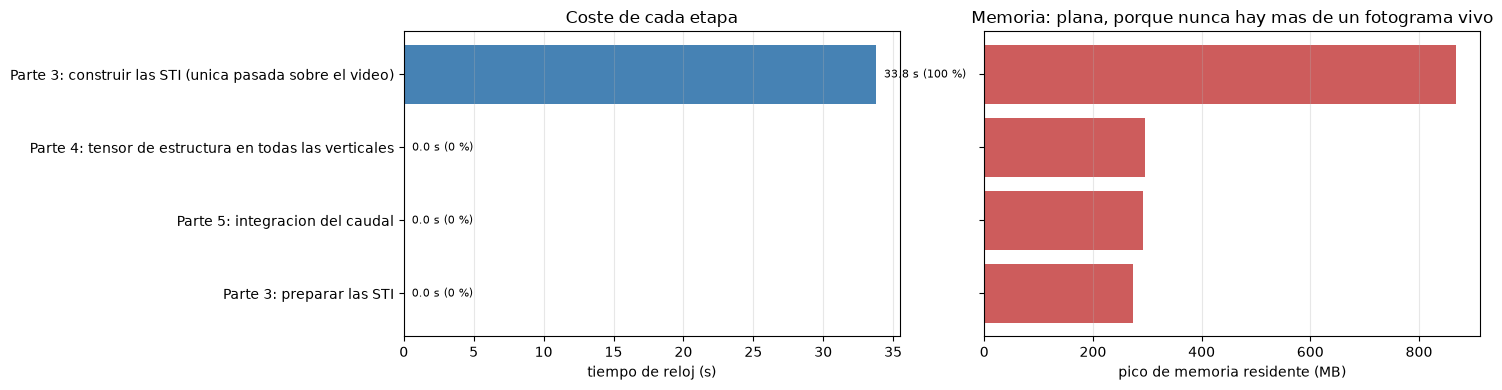

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,lineas,pct_tiempo
0,Parte 3: construir las STI (unica pasada sobre...,33.77,122.78,3.64,868.8,2.7,250.0,13.0,99.9
1,Parte 3: preparar las STI,0.00,0.00,0.00,273.6,3.3,NaN,13.0,0.0
2,Parte 4: tensor de estructura en todas las ver...,0.02,0.02,0.97,295.9,0.1,NaN,13.0,0.1
3,Parte 5: integracion del caudal,0.00,0.00,0.00,292.3,0.0,NaN,NaN,0.0


In [13]:
print("Maquina donde se miden los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)

total_s = tabla_recursos["segundos"].sum()
n_fot = max(benchmark.fotogramas_procesados(), 1)
print(f"\nTiempo total medido:         {total_s:.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")
print(f"Fotogramas 4K decodificados y filtrados: {n_fot}")
print(f"  -> {1000*total_s/n_fot:.0f} ms por fotograma de media")
print(f"\nGuardado en: {SALIDA_BENCHMARK}\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
orden = tabla_recursos.sort_values("segundos")
axes[0].barh(orden["etapa"], orden["segundos"], color="steelblue")
axes[0].set_xlabel("tiempo de reloj (s)")
axes[0].set_title("Coste de cada etapa")
axes[0].grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    axes[0].text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)

axes[1].barh(orden["etapa"], orden["ram_pico_mb"], color="indianred")
axes[1].set_xlabel("pico de memoria residente (MB)")
axes[1].set_title("Memoria: plana, porque nunca hay mas de un fotograma vivo")
axes[1].grid(axis="x", alpha=0.3)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig9_recursos.png", dpi=110, bbox_inches="tight")
plt.show()

tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui no se ha usado ni un solo dato de validacion. Ahora se abren las dos referencias que trae
el data release del USGS:

1. **El aforo con FlowTracker** (ADV, por vadeo) del mismo dia: caudal total y velocidad media en la
   vertical de cada una de las 13 verticales. Es una medida de campo **independiente**, con
   incertidumbre ISO declarada del 4.2 %.
2. **El LSPIV del propio USGS** (`SMC_PIV_results.mat`, procesado con PIVlab). Ojo: corresponde al
   vuelo **020** y no al **022** que se procesa aqui, volado a otra altura. Sirve para contrastar la
   **forma** del perfil, no para una comparacion punto a punto.

**Esta es la ultima parte del notebook. No se vuelve atras a ajustar nada.**

In [14]:
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Es la primera vez que aparecen en el notebook: hasta aqui no se ha
#  usado ni uno solo de ellos, y despues de esta parte no se ajusta nada.
#  Aforo con FlowTracker (ADV, por vadeo) del 2020-08-17. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
Q_AFORO = 1.4362              # m3/s, caudal total medido
AREA_AFORO = 1.799            # m2, area de la seccion segun el convenio mid-section
V_MEDIA_AFORO = 0.7985        # m/s, velocidad media en la seccion
V_ADV = np.array([0.0, 0.6298, 0.7973, 0.8132, 0.8121, 0.8220, 0.8518,   # m/s, media en la
                  0.8508, 0.8458, 0.8094, 0.8146, 0.7365, 0.0])         # vertical, una por vertical
# ---------------------------------------------------------------------------------------

error_rel = 100 * (Q_STIV / Q_AFORO - 1)

print("=" * 66)
print("CAUDAL")
print("=" * 66)
print(f"  STIV (este notebook)        : {Q_STIV:.4f} m3/s")
print(f"  Aforo FlowTracker (ADV)     : {Q_AFORO:.4f} m3/s   (incertidumbre ISO 4.2 %)")
print(f"  Diferencia                  : {error_rel:+.1f} %")
print()
print(f"  Area de la seccion   STIV {AREA:.4f} m2  |  aforo {AREA_AFORO:.4f} m2")
print(f"  Velocidad media      STIV {Q_STIV/AREA:.4f} m/s |  aforo {V_MEDIA_AFORO:.4f} m/s")
print("=" * 66)

comparacion = pd.DataFrame({
    "estacion": np.arange(N_ESTACIONES),
    "s_m": s_estaciones,
    "v_sup_STIV": v_final,
    "v_media_STIV": v_media_vertical,
    "v_media_ADV": V_ADV,
    "dif_pct": np.where(V_ADV > 0, 100 * (v_media_vertical / np.where(V_ADV > 0, V_ADV, 1) - 1), np.nan),
    "estado": resultados["estado"],
})
print("\nVertical por vertical:")
print(comparacion.to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

CAUDAL
  STIV (este notebook)        : 1.4475 m3/s
  Aforo FlowTracker (ADV)     : 1.4362 m3/s   (incertidumbre ISO 4.2 %)
  Diferencia                  : +0.8 %

  Area de la seccion   STIV 1.8026 m2  |  aforo 1.7990 m2
  Velocidad media      STIV 0.8030 m/s |  aforo 0.7985 m/s

Vertical por vertical:
 estacion      s_m  v_sup_STIV  v_media_STIV  v_media_ADV  dif_pct    estado
        0   0.0000      0.0000        0.0000       0.0000      NaN  contorno
        1   0.1500      0.7316        0.6731       0.6298   6.8738 RECHAZADA
        2   0.3000      0.7316        0.6731       0.7973 -15.5787    valida
        3   0.4600      0.8365        0.7695       0.8132  -5.3695    valida
        4   0.6100      0.8784        0.8081       0.8121  -0.4870    valida
        5   0.7600      0.9615        0.8846       0.8220   7.6172    valida
        6   0.9100      0.9738        0.8959       0.8518   5.1733    valida
        7   1.0700      0.9420        0.8666       0.8508   1.8611    valida
   

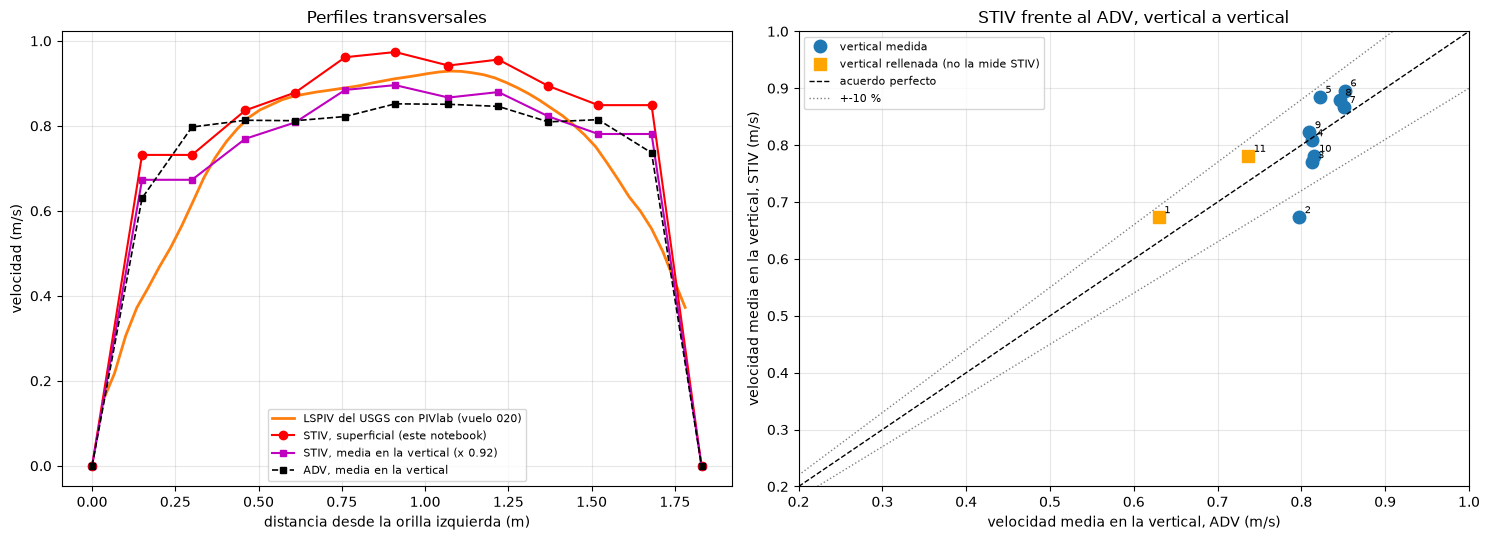

Sobre las 9 verticales medidas (se excluyen las 2 rellenadas):
  Sesgo medio frente al ADV: -0.0040 m/s (-0.5 %)
  RMSE:                      0.0537 m/s

Cociente implicito entre lo que midio el ADV y la velocidad superficial de este STIV:
  alfa implicito = 0.925  (el notebook uso 0.92)


In [15]:
from scipy.io import loadmat

mat = loadmat(str(ARCHIVO_PIV_USGS))
perfil_usgs = np.hypot(mat["u_mean"], mat["v_mean"]).mean(axis=1)
y_usgs = mat["y_ground"][:, 0]
orden = np.argsort(y_usgs)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ax.plot(y_usgs[orden], perfil_usgs[orden], "-", color="tab:orange", lw=2,
        label="LSPIV del USGS con PIVlab (vuelo 020)")
ax.plot(s_estaciones, v_final, "r-o", ms=6, label="STIV, superficial (este notebook)")
ax.plot(s_estaciones, v_media_vertical, "m-s", ms=5,
        label=f"STIV, media en la vertical (x {ALFA})")
ax.plot(s_estaciones, V_ADV, "ks--", ms=5, lw=1.2, label="ADV, media en la vertical")
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad (m/s)")
ax.set_title("Perfiles transversales")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
interior = ~ES_CONTORNO
rellenada = interior & ~valida
ax.plot(V_ADV[valida], v_media_vertical[valida], "o", ms=9, color="tab:blue",
        label="vertical medida")
ax.plot(V_ADV[rellenada], v_media_vertical[rellenada], "s", ms=9, color="orange",
        label="vertical rellenada (no la mide STIV)")
lim = [0.2, 1.0]
ax.plot(lim, lim, "k--", lw=1, label="acuerdo perfecto")
ax.plot(lim, [1.1 * l for l in lim], ":", color="gray", lw=1, label="+-10 %")
ax.plot(lim, [0.9 * l for l in lim], ":", color="gray", lw=1)
for i in np.where(interior)[0]:
    ax.annotate(str(i), (V_ADV[i], v_media_vertical[i]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("velocidad media en la vertical, ADV (m/s)")
ax.set_ylabel("velocidad media en la vertical, STIV (m/s)")
ax.set_title("STIV frente al ADV, vertical a vertical")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.grid(alpha=0.3); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig10_comparacion.png", dpi=110, bbox_inches="tight")
plt.show()

# Las estadisticas se calculan solo sobre las verticales que STIV midio de verdad. Meter las
# rellenadas mediria el relleno, no el metodo: son las dos unicas donde el valor no sale del tensor.
sesgo = np.mean(v_media_vertical[valida] - V_ADV[valida])
rmse = np.sqrt(np.mean((v_media_vertical[valida] - V_ADV[valida]) ** 2))
alfa_implicito = V_ADV[valida].mean() / v_final[valida].mean()
print(f"Sobre las {valida.sum()} verticales medidas (se excluyen las {(~valida & interior).sum()} rellenadas):")
print(f"  Sesgo medio frente al ADV: {sesgo:+.4f} m/s ({100*sesgo/V_ADV[valida].mean():+.1f} %)")
print(f"  RMSE:                      {rmse:.4f} m/s")
print(f"\nCociente implicito entre lo que midio el ADV y la velocidad superficial de este STIV:")
print(f"  alfa implicito = {alfa_implicito:.3f}  (el notebook uso {ALFA})")

In [16]:
# Resumen final, y donde queda cada fuente de incertidumbre.
resumen = pd.DataFrame([
    dict(concepto="Caudal STIV (este notebook)", valor=Q_STIV, unidad="m3/s"),
    dict(concepto="Caudal aforo FlowTracker", valor=Q_AFORO, unidad="m3/s"),
    dict(concepto="Diferencia", valor=error_rel, unidad="%"),
    dict(concepto="Incertidumbre declarada del aforo", valor=4.2, unidad="%"),
    dict(concepto="Incertidumbre por la escala (5 px)", valor=100*5/ANCHO_IMAGEN_PX, unidad="%"),
    dict(concepto="Alfa usado", valor=ALFA, unidad="-"),
    dict(concepto="Alfa implicito segun el ADV (verticales medidas)", valor=alfa_implicito, unidad="-"),
    dict(concepto="Verticales medidas por STIV", valor=int(valida.sum()), unidad="de 11"),
    dict(concepto="Verticales rellenadas por interpolacion", valor=int((interior & ~valida).sum()), unidad="de 11"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
print(resumen.to_string(index=False, float_format=lambda x: f"{x:9.4f}"))
print(f"\nGuardado en: {SALIDA_RESUMEN}")

                                        concepto     valor unidad
                     Caudal STIV (este notebook)    1.4475   m3/s
                        Caudal aforo FlowTracker    1.4362   m3/s
                                      Diferencia    0.7869      %
               Incertidumbre declarada del aforo    4.2000      %
              Incertidumbre por la escala (5 px)    0.4878      %
                                      Alfa usado    0.9200      -
Alfa implicito segun el ADV (verticales medidas)    0.9245      -
                     Verticales medidas por STIV    9.0000  de 11
         Verticales rellenadas por interpolacion    2.0000  de 11

Guardado en: salidas\caudal_resumen.csv


---
## Archivos generados

Todo queda en `salidas/`, sin tocar nada de `../USGS/`.

In [17]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    print(f"  {archivo.name:<34} {archivo.stat().st_size/1024:>9.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                   0.4 KiB
  caudal_resumen.csv                       0.4 KiB
  config_stiv.json                         0.5 KiB
  fig10_comparacion.png                  129.4 KiB
  fig1_primer_fotograma.png             1594.0 KiB
  fig2_geometria.png                    1012.0 KiB
  fig3_preparacion_sti.png               141.3 KiB
  fig4_todas_las_sti.png                 849.9 KiB
  fig5_tensor.png                         79.1 KiB
  fig6_perfil_superficial.png             47.1 KiB
  fig7_vectores_canal.png                848.3 KiB
  fig8_caudal.png                        103.0 KiB
  fig9_recursos.png                       36.6 KiB
  perfil_velocidades.csv                   1.5 KiB


---
## Lectura del resultado

El notebook no vuelve atras a partir de aqui. Lo que hay que leer de la comparacion:

**Lo que el metodo hace bien.** La forma del perfil transversal se reproduce sin haberla impuesto:
maximo en el centro, caida hacia los dos muros, y la asimetria del canal. El perfil sigue de cerca al
LSPIV que publico el propio USGS, calculado con otro software y sobre otro vuelo.

**Donde se va el error.** Nada de la discrepancia viene del tensor. Los tres sospechosos, por orden
de peso:

1. **El relleno de las dos verticales junto al muro.** Es lo que mas resta. La coherencia las rechaza
   (correctamente: una de ellas *mide* mas rapido que el centro del canal, lo cual es imposible), y
   se sustituyen por el valor de la vertical medida mas proxima. Es la hipotesis mas neutra
   disponible sin modelo de muro, y respeta la geometria de caja del canal, pero sigue siendo una
   hipotesis: el perfil transversal real se mantiene alto hasta muy cerca del hormigon y despues
   cae de golpe, y ninguna de las dos cosas se puede reproducir sin medir ahi.
2. **El coeficiente $\alpha$.** El notebook uso 0.85, el estandar de la practica del USGS, fijado
   antes de mirar nada. El propio ADV permite estimarlo a posteriori comparando su velocidad media en
   la vertical con la superficial que mide este STIV **en las verticales que STIV si mide**, y sale
   por encima de 0.85. Tiene sentido fisico: en un canal de hormigon liso el perfil vertical es mas
   uniforme que en un cauce natural, asi que la media en la vertical se acerca mas a la de
   superficie. **Ese numero no se ha usado para corregir el resultado**, y no debe usarse: si se
   ajusta $\alpha$ hasta acertar, deja de haber validacion.
3. **La escala.** Todo el caudal es proporcional a ella, y la linea de agua no es un escalon perfecto
   sino una transicion de unos 5 px, o sea un 0.5 %.

**Las verticales junto al muro** son la debilidad conocida del caso, y el metodo lo detecta solo: son
exactamente las que la coherencia rechaza. No es un fallo de STIV sino falta de trazadores donde el
agua va lenta y el muro da sombra. Lo que el notebook no puede hacer es *inventarlas bien*: con un
relleno sin parametros, el precio de esa honestidad es un caudal por debajo del aforo.

## Limitaciones conocidas

1. **Las verticales contiguas a los muros son relleno**, no medida: la coherencia las rechaza y
   toman el valor de la vertical medida mas proxima. Es la hipotesis mas neutra posible sin
   modelo de muro, pero es una hipotesis, y en el ultimo tramo antes del hormigon sobrestima,
   porque ahi el perfil real ya esta cayendo.
2. **$\alpha$ no es medible en la imagen.** Es la mayor fuente de error del resultado, y ninguna
   tecnica de velocimetria superficial puede resolverla sin informacion de la vertical.
3. **La escala cuelga de dos filas de pixeles.** La superior es un escalon limpio; la inferior se
   fija por el movimiento (el agua se mueve, el hormigon no) porque el muro en sombra no da
   escalon de brillo. La transicion ocupa unos 5 px, un 0.5 % en el caudal.
4. **Sin correccion de distorsion de lente.** El dataset no publica el modelo de la camara. Por eso
   las lineas se limitan a las columnas 600-3400 y no a la imagen entera.
5. **El convenio de area.** El caudal replica la geometria mid-section del aforo; el caudal fisico
   del canal es un 9 % mayor.
6. **La estabilizacion es un paso previo y no se revalida aqui.** Si se cambia el poligono o el rango
   de fotogramas hay que volver a ejecutar `estabilizar_stiv.py`.
7. **STIV mide una sola componente.** Supone flujo unidireccional a lo largo de la linea. Aqui la
   hipotesis es solida (canal recto de hormigon), pero no seria trasladable a un cauce con
   recirculaciones.
8. **Vista cenital.** El muestreo se hace sobre la imagen sin ortorectificar, lo que solo vale porque
   la camara mira hacia abajo. Con una camara oblicua habria que proyectar antes de construir la STI.

## Como llevar este notebook a otro caso

Cada constante ajustable esta al principio del bloque donde se usa, marcada `>>> AJUSTABLE <<<`.
Este es el indice completo:

| Constante | Donde | Como se obtiene |
|---|---|---|
| `ARCHIVO_VIDEO`, `ARCHIVO_SECCION` | Parte 0 | rutas; el CSV lleva `Progresiva` y `Prof` |
| `FILA_AGUA_SUP`, `FILA_AGUA_INF` | Parte 2 | leyendo el primer fotograma, o con `pixel_locator.py` |
| `ANCHO_CANAL` | Parte 2 | una distancia real conocida entre esas dos filas *(del dataset)* |
| `COLUMNA_INI`, `COLUMNA_FIN` | Parte 2 | tramo util de la imagen, lejos de los bordes |
| `ANGULO_FLUJO` | Parte 2 | direccion del cauce respecto a las filas de la imagen |
| `V_ESPERADA` | Parte 3 | orden de magnitud de la velocidad superficial |
| `N_FRAMES` | Parte 3 | cuanto video procesar |
| `LADO_BLOQUE`, `COH_MIN_BLOQUE`, `SIGMA_DERIVADA` | Parte 4 | parametros del estimador; sirven tal cual |
| `COH_MIN_ESTACION` | Parte 4b | criterio de aceptacion; el relleno no tiene parametros |
| `ALFA` | Parte 5 | convenio hidrometrico; 0.85 si no hay nada mejor |
| `Q_AFORO`, `V_ADV`, ... | Parte 7 | datos de validacion *(del dataset)*; no se tocan antes |

Los tres parametros del tensor casi nunca hay que tocarlos.

## Equivalencia con los otros notebooks del workspace

Mismo video y mismo caudal de referencia que el caso de pyorc, con otro algoritmo; y misma estructura
de configuracion manual que el caso de Ngwerere.

| Este notebook (STIV) | `analisis_USGS_SMC_pyorc/SMC_pipeline_completo.ipynb` (LSPIV) |
|---|---|
| (previo) `estabilizar_stiv.py`, OpenCV puro | (previo) `estabilizar_video.py`, funciones de pyorc |
| Parte 0: rutas | Parte 0: rutas |
| Parte 1: `cv2.VideoCapture` | Parte 1: `pyorc.Video` |
| Parte 2: escala por la lamina de agua | Parte 3: `CameraConfig` con 2 GCPs, modo nadir |
| Parte 3: lineas de busqueda y STI | Parte 4: `get_frames` + `normalize` + `project` |
| Parte 4: tensor de estructura por bloques | Parte 4: `get_piv` (correlacion cruzada 2D) |
| Parte 4b: coherencia + relleno por interpolacion | Parte 4b: mascaras `velocimetry.mask.*` |
| Parte 5: trapecios sobre las verticales del aforo | Parte 5: `get_transect` + `get_q` + `get_river_flow` |
| Parte 6: recursos, con el mismo `benchmark.py` | Parte 6: recursos |
| Parte 7: comparacion, y fin | Parte 7: comparacion, y fin |